In [4]:
import pandas as pd

# New section

In [6]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv("Dataset .csv")


Saving Dataset .csv to Dataset  (1).csv


In [7]:
print(df.shape)

(9551, 21)


In [8]:
print(df.columns)

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='object')


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

In [10]:
df.describe()

,Restaurant ID,Country Code,Longitude,Latitude,Average Cost for two,Price range,Aggregate rating,Votes
count,9.551000e+03,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000,9551.000000
mean,9.051128e+06,18.365616,64.126574,25.854381,1199.210763,1.804837,2.666370,156.909748
std,8.791521e+06,56.750546,41.467058,11.007935,16121.183073,0.905609,1.516378,430.169145
min,5.300000e+01,1.000000,-157.948486,-41.330428,0.000000,1.000000,0.000000,0.000000
25%,3.019625e+05,1.000000,77.081343,28.478713,250.000000,1.000000,2.500000,5.000000
50%,6.004089e+06,1.000000,77.191964,28.570469,400.000000,2.000000,3.200000,31.000000
75%,1.835229e+07,1.000000,77.282006,28.642758,700.000000,2.000000,3.700000,131.000000
max,1.850065e+07,216.000000,174.832089,55.976980,800000.000000,4.000000,4.900000,10934.000000


In [12]:
print(df.isnull().sum())

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                9
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64


In [14]:
print(df.duplicated().sum())

0


In [15]:
df['Cuisines'] = df['Cuisines'].fillna('Unknown')

In [16]:
print(df.isnull().sum())

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                0
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64


In [17]:
df = df[df['Aggregate rating'] > 0]

print(df.shape)

(7403, 21)


In [18]:
columns_to_drop = [
    'Restaurant ID',
    'Restaurant Name',
    'Address',
    'Locality Verbose',
    'Rating color',
    'Rating text'
]

df = df.drop(columns=columns_to_drop)

print(df.head())

   Country Code              City                                    Locality  \
0           162       Makati City   Century City Mall, Poblacion, Makati City   
1           162       Makati City  Little Tokyo, Legaspi Village, Makati City   
2           162  Mandaluyong City  Edsa Shangri-La, Ortigas, Mandaluyong City   
3           162  Mandaluyong City      SM Megamall, Ortigas, Mandaluyong City   
4           162  Mandaluyong City      SM Megamall, Ortigas, Mandaluyong City   

    Longitude   Latitude                          Cuisines  \
0  121.027535  14.565443        French, Japanese, Desserts   
1  121.014101  14.553708                          Japanese   
2  121.056831  14.581404  Seafood, Asian, Filipino, Indian   
3  121.056475  14.585318                   Japanese, Sushi   
4  121.057508  14.584450                  Japanese, Korean   

   Average Cost for two          Currency Has Table booking  \
0                  1100  Botswana Pula(P)               Yes   
1             

In [19]:
categorical_columns = df.select_dtypes(
    include='object'
).columns

print(categorical_columns)

Index(['City', 'Locality', 'Cuisines', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu'],
      dtype='object')


In [20]:
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

print(numerical_columns)

Index(['Country Code', 'Longitude', 'Latitude', 'Average Cost for two',
       'Price range', 'Aggregate rating', 'Votes'],
      dtype='object')


In [21]:
print("Dataset shape:", df.shape)

print("Missing values:")
print(df.isnull().sum())

print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (7403, 15)
Missing values:
Country Code            0
City                    0
Locality                0
Longitude               0
Latitude                0
Cuisines                0
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Votes                   0
dtype: int64
Duplicate rows: 0


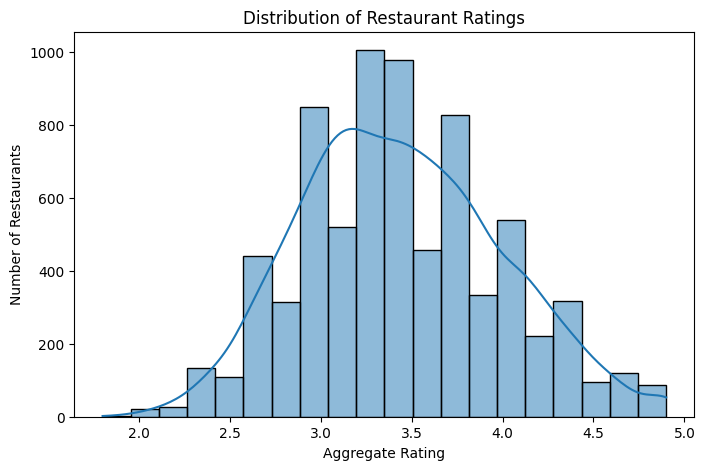

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Aggregate rating',
    bins=20,
    kde=True
)

plt.title('Distribution of Restaurant Ratings')
plt.xlabel('Aggregate Rating')
plt.ylabel('Number of Restaurants')

plt.show()

In [23]:
average_rating = df['Aggregate rating'].mean()

print("Average Restaurant Rating:", average_rating)

Average Restaurant Rating: 3.440024314467108


In [24]:
print(df['Aggregate rating'].describe())

count    7403.000000
mean        3.440024
std         0.552195
min         1.800000
25%         3.000000
50%         3.400000
75%         3.800000
max         4.900000
Name: Aggregate rating, dtype: float64


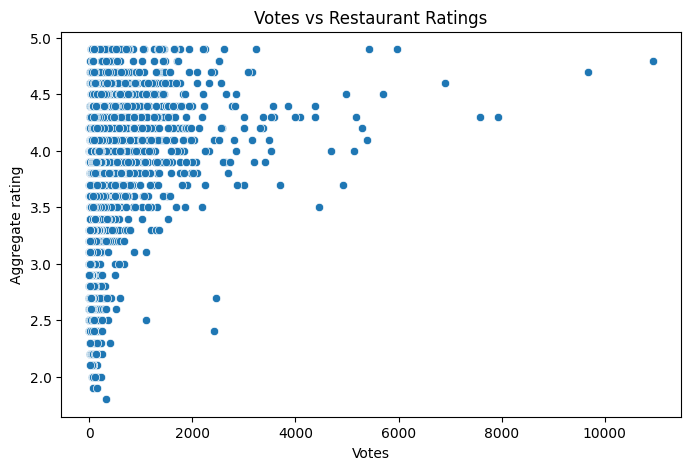

In [25]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Votes',
    y='Aggregate rating'
)

plt.title('Votes vs Restaurant Ratings')
plt.show()

In [26]:
correlation = df.corr(numeric_only=True)

print(correlation)

                      Country Code  Longitude  Latitude  Average Cost for two  \
Country Code              1.000000  -0.736241  0.010346              0.039305   
Longitude                -0.736241   1.000000 -0.097542              0.049345   
Latitude                  0.010346  -0.097542  1.000000             -0.124947   
Average Cost for two      0.039305   0.049345 -0.124947              1.000000   
Price range               0.210459  -0.074384 -0.221437              0.070638   
Aggregate rating          0.412917  -0.291458 -0.179917              0.076790   
Votes                     0.127652  -0.085230 -0.038285              0.063424   

                      Price range  Aggregate rating     Votes  
Country Code             0.210459          0.412917  0.127652  
Longitude               -0.074384         -0.291458 -0.085230  
Latitude                -0.221437         -0.179917 -0.038285  
Average Cost for two     0.070638          0.076790  0.063424  
Price range              1.0000

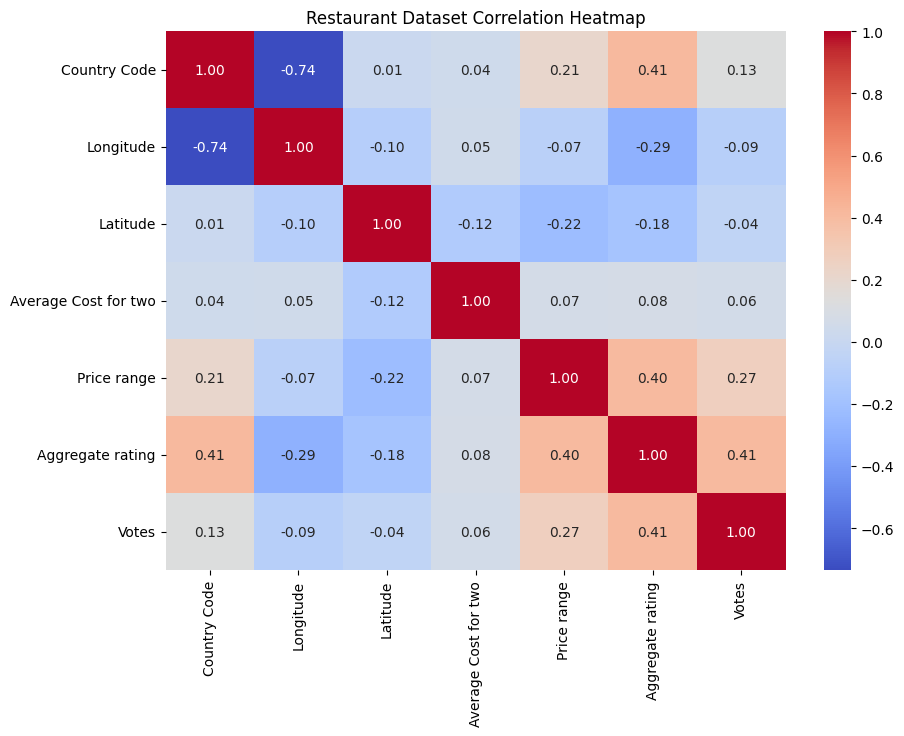

In [27]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Restaurant Dataset Correlation Heatmap')

plt.show()

In [28]:
price_rating = df.groupby(
    'Price range'
)['Aggregate rating'].mean()

print(price_rating)

Price range
1    3.238885
2    3.377167
3    3.777276
4    3.890957
Name: Aggregate rating, dtype: float64


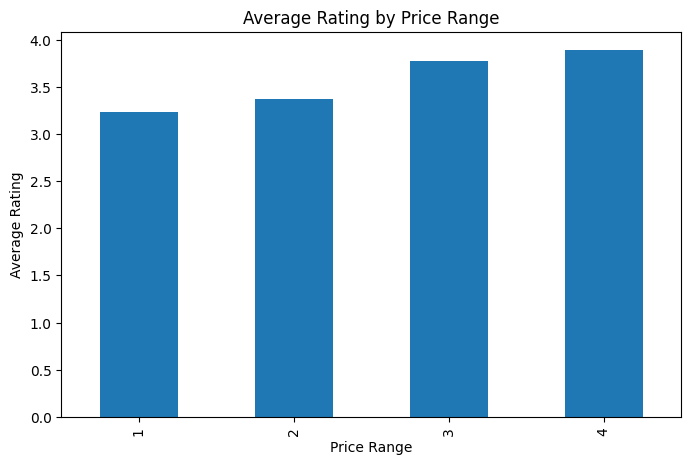

In [29]:
price_rating.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Rating by Price Range')
plt.xlabel('Price Range')
plt.ylabel('Average Rating')

plt.show()

In [30]:
votes_correlation = df[
    'Votes'
].corr(df['Aggregate rating'])

print("Votes correlation:", votes_correlation)

Votes correlation: 0.40901786341810925


In [31]:
price_rating = df.groupby(
    'Price range'
)['Aggregate rating'].mean()

print(price_rating)

Price range
1    3.238885
2    3.377167
3    3.777276
4    3.890957
Name: Aggregate rating, dtype: float64


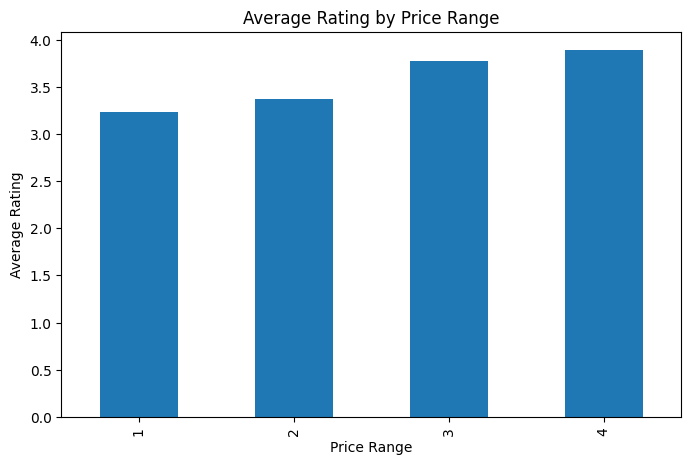

In [32]:
price_rating.plot(kind='bar', figsize=(8, 5))

plt.title('Average Rating by Price Range')
plt.xlabel('Price Range')
plt.ylabel('Average Rating')
plt.show()

In [33]:
X = df.drop('Aggregate rating', axis=1)

y = df['Aggregate rating']

In [34]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (7403, 14)
y shape: (7403,)


In [35]:
X['Country Code'] = X['Country Code'].astype(str)

categorical_features = X.select_dtypes(
    include='object'
).columns.tolist()

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical features:", categorical_features)

print("Numerical features:", numerical_features)

Categorical features: ['Country Code', 'City', 'Locality', 'Cuisines', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu']
Numerical features: ['Longitude', 'Latitude', 'Average Cost for two', 'Price range', 'Votes']


In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5922, 14)
Testing features: (1481, 14)
Training target: (5922,)
Testing target: (1481,)


In [37]:
categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical:", categorical_features)
print("Numerical:", numerical_features)

Categorical: ['Country Code', 'City', 'Locality', 'Cuisines', 'Currency', 'Has Table booking', 'Has Online delivery', 'Is delivering now', 'Switch to order menu']
Numerical: ['Longitude', 'Latitude', 'Average Cost for two', 'Price range', 'Votes']


In [38]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

In [39]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),

        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [41]:
X_train_processed = preprocessor.fit_transform(X_train)

In [42]:
X_test_processed = preprocessor.transform(X_test)

In [43]:
print("Training:", X_train_processed.shape)
print("Testing:", X_test_processed.shape)

Training: (5922, 2689)
Testing: (1481, 2689)


In [44]:
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error, r2_score

In [45]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

In [46]:
results = {}

trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('model', model)
    ])


    pipeline.fit(X_train, y_train)


    predictions = pipeline.predict(X_test)

    mse = mean_squared_error(y_test, predictions)

    rmse = mse ** 0.5

    r2 = r2_score(y_test, predictions)

    results[name] = {
        'MSE': mse,
        'RMSE': rmse,
        'R2 Score': r2
    }

    trained_models[name] = pipeline

    print("\nModel:", name)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R2 Score:", r2)


Model: Linear Regression
MSE: 0.16737452002289277
RMSE: 0.40911431168182416
R2 Score: 0.4588261569795852

Model: Decision Tree
MSE: 0.19807562457798783
RMSE: 0.44505687791336046
R2 Score: 0.3595599440889977

Model: Random Forest
MSE: 0.111791428089129
RMSE: 0.3343522515089871
R2 Score: 0.6385435683552099


In [47]:
results_df = pd.DataFrame(results).T

print(results_df)

                        MSE      RMSE  R2 Score
Linear Regression  0.167375  0.409114  0.458826
Decision Tree      0.198076  0.445057  0.359560
Random Forest      0.111791  0.334352  0.638544


In [48]:
results_df = results_df.sort_values(
    by='RMSE',
    ascending=True
)

print(results_df)

                        MSE      RMSE  R2 Score
Random Forest      0.111791  0.334352  0.638544
Linear Regression  0.167375  0.409114  0.458826
Decision Tree      0.198076  0.445057  0.359560


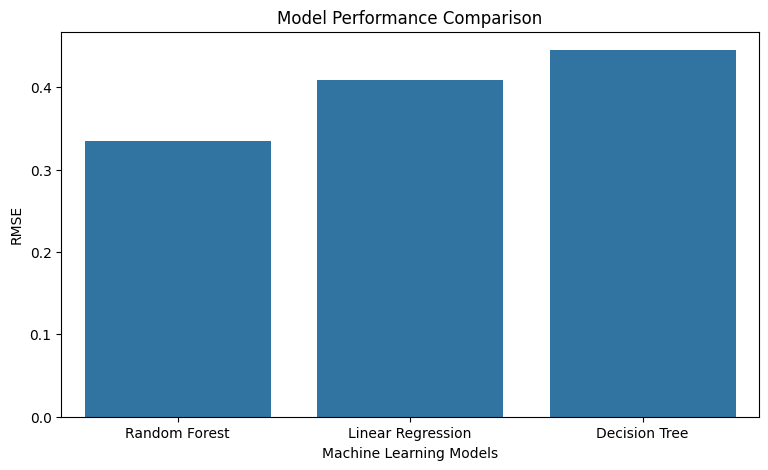

In [49]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=results_df.index,
    y=results_df['RMSE']
)

plt.title('Model Performance Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('RMSE')

plt.show()

In [50]:
best_model_name = results_df.index[0]

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest


In [51]:
best_predictions = best_model.predict(X_test)

In [52]:
comparison = pd.DataFrame({
    'Actual Rating': y_test.values,
    'Predicted Rating': best_predictions
})

print(comparison.head(10))

   Actual Rating  Predicted Rating
0            2.9             2.928
1            3.9             3.196
2            2.8             2.726
3            2.3             2.967
4            3.2             3.080
5            3.0             3.150
6            3.8             3.727
7            3.3             3.615
8            2.5             2.895
9            3.4             3.428


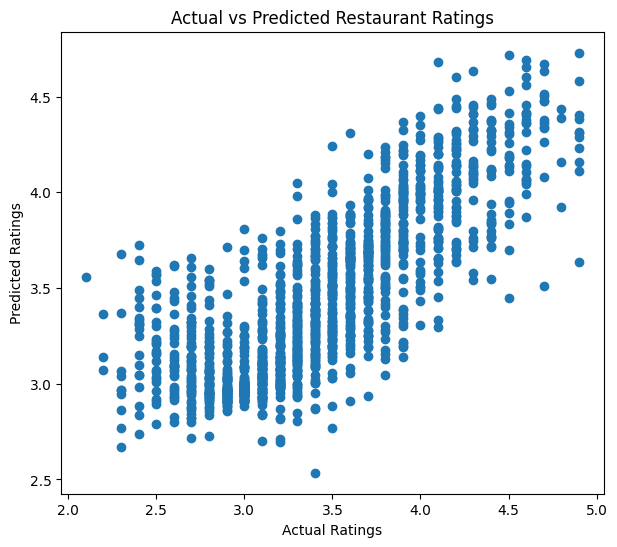

In [53]:
plt.figure(figsize=(7, 6))

plt.scatter(y_test, best_predictions)

plt.xlabel('Actual Ratings')
plt.ylabel('Predicted Ratings')

plt.title('Actual vs Predicted Restaurant Ratings')

plt.show()

In [54]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [55]:
best_model_name = results_df['RMSE'].idxmin()

best_model = trained_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: Random Forest


In [56]:
importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1
)

In [57]:
importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': importance.importances_mean
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df)

                 Feature    Importance
13                 Votes  2.479101e-01
4               Latitude  3.062263e-02
3              Longitude  2.584344e-02
6   Average Cost for two  1.663587e-02
5               Cuisines  1.386378e-02
0           Country Code  6.333046e-03
7               Currency  6.261844e-03
9    Has Online delivery  2.451999e-03
1                   City  1.605553e-03
8      Has Table booking  9.496071e-04
12           Price range  5.696672e-04
2               Locality  5.226072e-04
11  Switch to order menu  5.551115e-18
10     Is delivering now -8.072895e-05


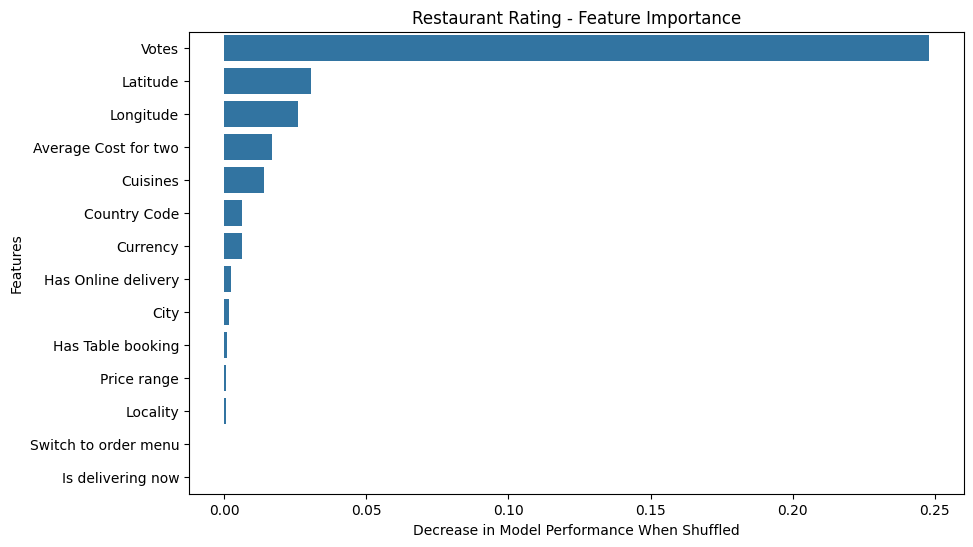

In [58]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature'
)

plt.title('Restaurant Rating - Feature Importance')
plt.xlabel('Decrease in Model Performance When Shuffled')
plt.ylabel('Features')

plt.show()

In [59]:
sample_restaurant = X_test.iloc[[0]]

predicted_rating = best_model.predict(sample_restaurant)

actual_rating = y_test.iloc[0]

print("Predicted Rating:", predicted_rating[0])

print("Actual Rating:", actual_rating)

Predicted Rating: 2.928000000000001
Actual Rating: 2.9


In [60]:
def predict_restaurant_rating(restaurant_data):

    prediction = best_model.predict(restaurant_data)

    return round(float(prediction[0]), 2)

In [61]:
new_restaurant = X_test.iloc[[5]]

rating = predict_restaurant_rating(new_restaurant)

print("Predicted Restaurant Rating:", rating)

Predicted Restaurant Rating: 3.15
